# 05 — Arrival Efficiency & Machine Learning Study (Gold Consumer)

This notebook delivers the comprehensive investigation answering the core question of the study:
> **"How much time and fuel do flights lose before landing at Paris-CDG (LFPG), Toulouse-Blagnac (LFBO) and Stavanger (ENZV) — with London-Heathrow (EGLL) and Frankfurt (EDDF) as references — when, why, and what could be improved?"**

All indicators are consumed directly from the **Gold layer** tables and the **Silver** arrival tables without requiring heavy transforms or raw event reprocessing:
- **Indicator A (Additional Arrival Transit Time / ASMA-like)**: 100 NM entry ring linear interpolation to touchdown compared against an empirical unimpeded 20th-percentile reference with fallback hierarchy (`RUNWAY_CLASS_SECTOR` -> `CLASS_SECTOR` -> `AIRPORT`).
- **Indicator B (Vertical CDO Efficiency & Holding Stacks)**: 200 NM descent window, level-off segmentation by altitude bands (`<FL70`, `FL70-100`, `FL100-200`, `>=FL200`), geometric holding pattern detection, fuel overconsumption (25 kg/min), and CO2 emissions (3.16 kg/kg fuel).
- **Machine Learning**: `GBTRegressor` explanatory model, feature importance, peak-demand smoothing scenarios, and `KMeans` airport typology.
- **Temporal Regularity**: Strict filtering of incomplete European traffic hours (< 50% median).


In [1]:
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
import opdi_pipeline
from opdi_pipeline.config import load_settings
from opdi_pipeline.spark import get_spark

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

prod_success = (Path.home() / "opdi-data" / "gold" / "_SUCCESS").exists()
ENV = "prod" if prod_success else "dev"
settings = load_settings(ENV)
spark = get_spark(settings)
print(f"{ENV.upper()}: scope [{settings.start}, {settings.end}[ | root: {settings.data_root} | Spark {spark.version}")


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/09 16:31:46 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


PROD: scope [2026-06-01, 2026-07-29[ | root: /home/ubuntu/opdi-data | Spark 3.5.0


## Data Ingestion & Readiness Check
Gold tables are loaded via Spark and transferred to Pandas dataframes for analysis.


In [2]:
marker = settings.gold_dir / "_SUCCESS"
assert marker.exists(), f"Gold _SUCCESS marker not found in {settings.gold_dir}"

arr_daily = spark.read.parquet(str(settings.gold_dir / "airport_arrival_daily")).toPandas()
arr_hourly = spark.read.parquet(str(settings.gold_dir / "airport_arrival_hourly")).toPandas()
hotspots = spark.read.parquet(str(settings.gold_dir / "holding_hotspots")).toPandas()
typology = spark.read.parquet(str(settings.gold_dir / "airport_typology")).toPandas()
airports_dim = spark.read.parquet(str(settings.silver_dir / "airports")).toPandas()

fi_path = settings.gold_dir / "ml_feature_importance"
feat_imp = spark.read.parquet(str(fi_path)).toPandas() if fi_path.exists() else pd.DataFrame()

scen_path = settings.gold_dir / "ml_scenarios"
scenarios = spark.read.parquet(str(scen_path)).toPandas() if scen_path.exists() else pd.DataFrame()

FOCUS_AIRPORTS = ["LFPG", "LFBO", "ENZV", "EGLL", "EDDF"]
print(f"Loaded {len(arr_daily):,} daily arrival rows across {arr_daily['airport_icao'].nunique()} airports.")
print(f"Loaded {len(arr_hourly):,} hourly records, {len(hotspots):,} holding hotspot cells, and {len(typology):,} clustered airports.")


Loaded 41,334 daily arrival rows across 953 airports.
Loaded 381,863 hourly records, 20,438 holding hotspot cells, and 685 clustered airports.


## 1. European Arrival Efficiency & Airport Typology Maps
The map below projects all European airports using geographic coordinates (latitude and longitude). 
The network background is rendered using all European aerodromes from `silver/airports`, while active commercial airports are colored by average additional arrival time and by airport operational cluster.


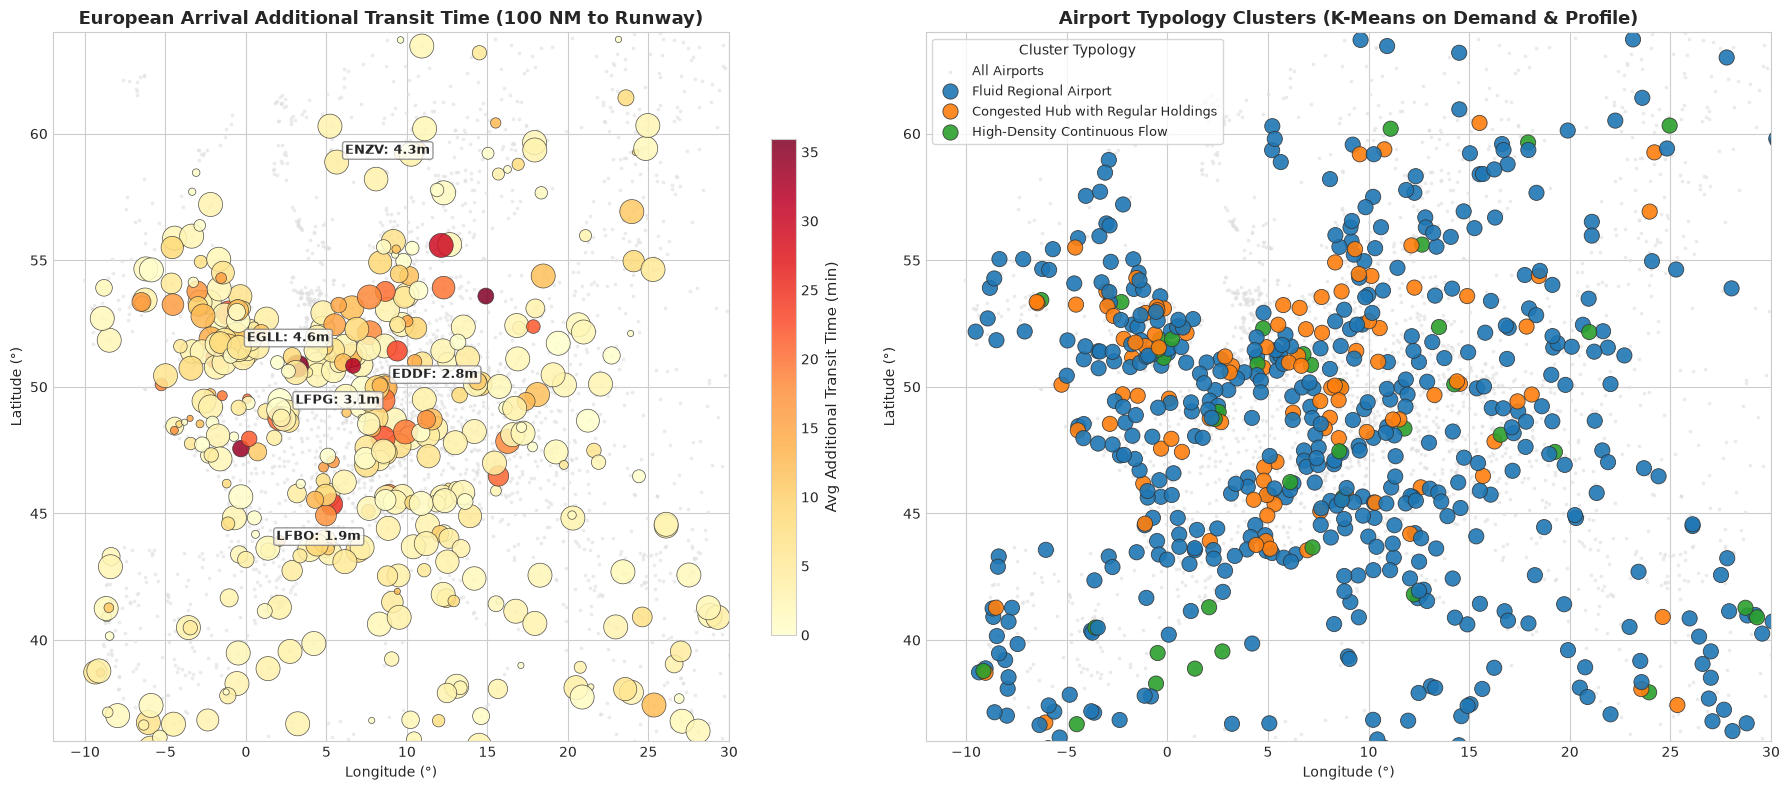

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

euro_bg = airports_dim[(airports_dim["longitude"].between(-15, 35)) & (airports_dim["latitude"].between(35, 65))]
ax1.scatter(euro_bg["longitude"], euro_bg["latitude"], s=3, color="#e0e0e0", alpha=0.5, label="All Airports")
ax2.scatter(euro_bg["longitude"], euro_bg["latitude"], s=3, color="#e0e0e0", alpha=0.5, label="All Airports")

summary_airports = (
    arr_daily.groupby(["airport_icao", "airport_name"], as_index=False)
    .agg(
        total_arrivals=("arrivals", "sum"),
        avg_additional_min=("avg_additional_min", "mean"),
        pct_with_holding=("pct_with_holding", "mean")
    )
    .merge(airports_dim[["airport_icao", "longitude", "latitude"]], on="airport_icao", how="inner")
)

sc1 = ax1.scatter(
    summary_airports["longitude"], summary_airports["latitude"],
    c=summary_airports["avg_additional_min"], cmap="YlOrRd",
    s=np.clip(summary_airports["total_arrivals"] / 5, 20, 300),
    alpha=0.85, edgecolors="#333333", linewidths=0.5
)
cbar1 = plt.colorbar(sc1, ax=ax1, shrink=0.7)
cbar1.set_label("Avg Additional Transit Time (min)", fontsize=11)
ax1.set_title("European Arrival Additional Transit Time (100 NM to Runway)", fontsize=13, fontweight="bold")
ax1.set_xlabel("Longitude (°)")
ax1.set_ylabel("Latitude (°)")

for icao in FOCUS_AIRPORTS:
    row = summary_airports[summary_airports["airport_icao"] == icao]
    if not row.empty:
        r = row.iloc[0]
        label_text = f"{icao}: {r['avg_additional_min']:.1f}m"
        ax1.annotate(label_text, (r["longitude"], r["latitude"]),
                     xytext=(6, 6), textcoords="offset points", fontweight="bold", fontsize=9,
                     bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, ec="gray"))

if not typology.empty:
    merged_typ = typology.merge(airports_dim[["airport_icao", "longitude", "latitude"]], on="airport_icao", how="inner")
    palette = sns.color_palette("tab10", n_colors=merged_typ["cluster_label"].nunique())
    sns.scatterplot(
        data=merged_typ, x="longitude", y="latitude", hue="cluster_label",
        palette=palette, s=120, ax=ax2, edgecolors="#333333", linewidth=0.6, alpha=0.9
    )
    ax2.set_title("Airport Typology Clusters (K-Means on Demand & Profile)", fontsize=13, fontweight="bold")
    ax2.set_xlabel("Longitude (°)")
    ax2.set_ylabel("Latitude (°)")
    ax2.legend(title="Cluster Typology", loc="upper left", frameon=True, fontsize=9)

for ax in (ax1, ax2):
    ax.set_xlim(-12, 30)
    ax.set_ylim(36, 64)

plt.tight_layout()
plt.show()


## 2. Spatial Holding Hotspots around Major Hubs (LFPG & EGLL)
Holding pattern locations (`gold/holding_hotspots`) around Paris-CDG (`LFPG`) and London-Heathrow (`EGLL`), plotted with concentric distance rings at 40 NM and 100 NM to observe the entry stack geometry.


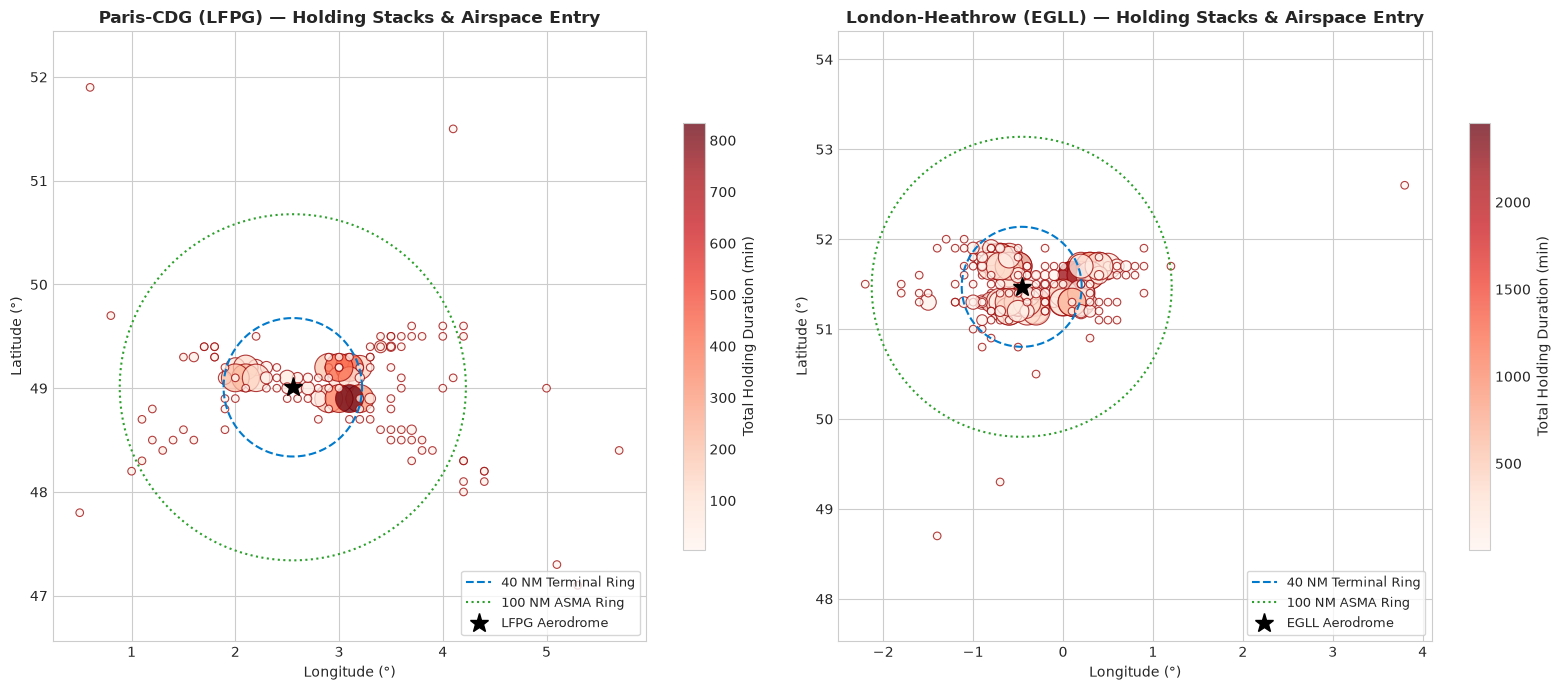

In [4]:
def plot_holding_ring(airport_icao, ax, title_prefix):
    apt = airports_dim[airports_dim["airport_icao"] == airport_icao]
    if apt.empty:
        return
    apt_lat, apt_lon = apt.iloc[0]["latitude"], apt.iloc[0]["longitude"]
    
    h_apt = hotspots[hotspots["airport_icao"] == airport_icao]
    
    r40_deg = 40.0 * 1.852 / 111.0
    r100_deg = 100.0 * 1.852 / 111.0
    theta = np.linspace(0, 2*np.pi, 200)
    
    ax.plot(apt_lon + r40_deg * np.cos(theta), apt_lat + r40_deg * np.sin(theta),
            "--", color="#007acc", linewidth=1.5, label="40 NM Terminal Ring")
    ax.plot(apt_lon + r100_deg * np.cos(theta), apt_lat + r100_deg * np.sin(theta),
            ":", color="#2ca02c", linewidth=1.5, label="100 NM ASMA Ring")
    
    if not h_apt.empty:
        sc = ax.scatter(
            h_apt["lon_cell"], h_apt["lat_cell"],
            s=np.clip(h_apt["holdings"] * 15, 30, 400),
            c=h_apt["holding_minutes"], cmap="Reds",
            alpha=0.75, edgecolors="#990000", linewidths=0.8
        )
        cbar = plt.colorbar(sc, ax=ax, shrink=0.7)
        cbar.set_label("Total Holding Duration (min)", fontsize=10)
    
    ax.plot(apt_lon, apt_lat, "k*", markersize=14, label=f"{airport_icao} Aerodrome")
    ax.set_title(f"{title_prefix} ({airport_icao}) — Holding Stacks & Airspace Entry", fontsize=12, fontweight="bold")
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_aspect("equal", adjustable="datalim")
    ax.legend(loc="lower right", frameon=True, fontsize=9)

fig, (ax_cdg, ax_lhr) = plt.subplots(1, 2, figsize=(16, 7))
plot_holding_ring("LFPG", ax_cdg, "Paris-CDG")
plot_holding_ring("EGLL", ax_lhr, "London-Heathrow")
plt.tight_layout()
plt.show()


## 3. Temporal Congestion Heatmaps: Hour of Day × Day of Week
Heatmaps showing `avg_additional_min` by hour of the day (0–23 UTC) and day of the week for the 5 focus airports, identifying acute rush periods and off-peak baseline operations.


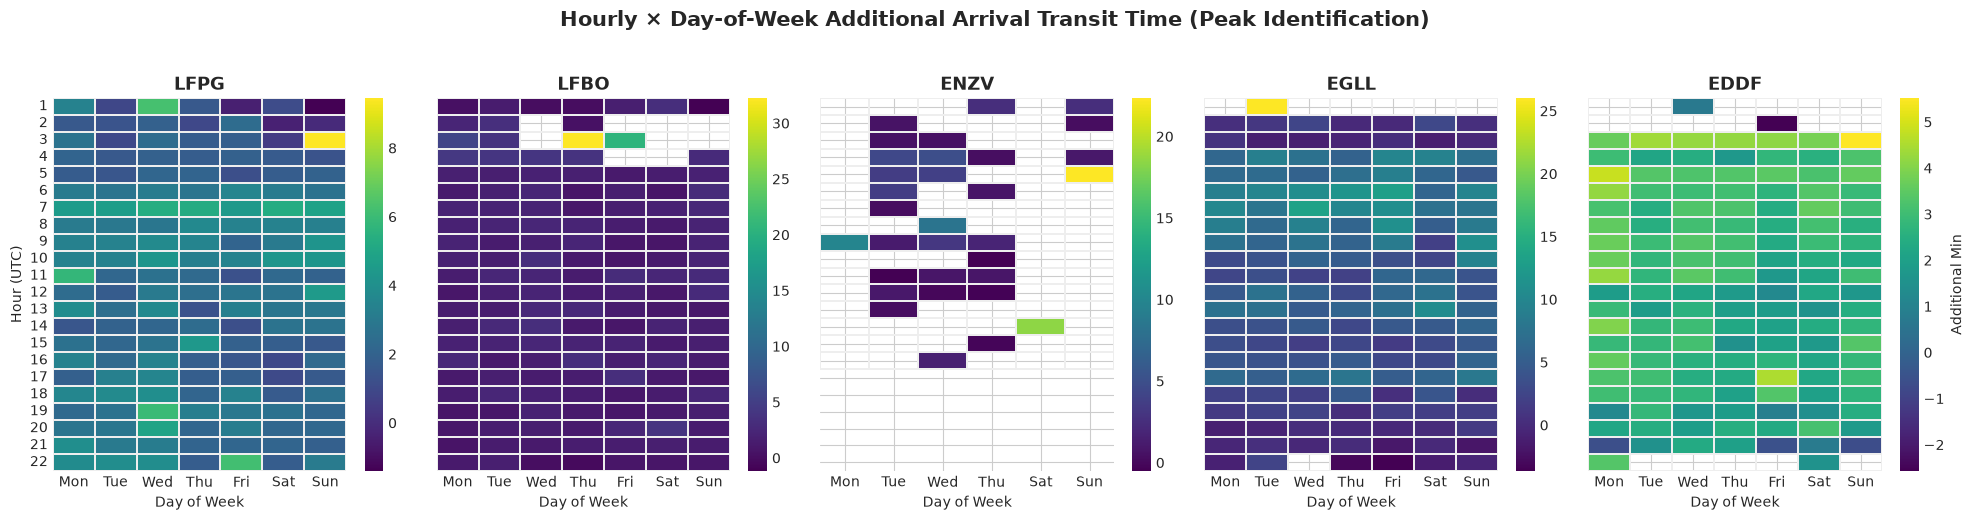

In [5]:
days_map = {1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri", 7: "Sat"}
hourly_focus = arr_hourly[arr_hourly["airport_icao"].isin(FOCUS_AIRPORTS)].copy()
hourly_focus["day_of_week"] = pd.to_datetime(hourly_focus["movement_date"]).dt.dayofweek + 1
hourly_focus["day_name"] = hourly_focus["day_of_week"].map(days_map)

fig, axes = plt.subplots(1, len(FOCUS_AIRPORTS), figsize=(20, 5), sharey=True)

for i, icao in enumerate(FOCUS_AIRPORTS):
    sub = hourly_focus[hourly_focus["airport_icao"] == icao]
    if sub.empty:
        axes[i].set_title(f"{icao} (No Data)")
        continue
    
    pivot = sub.pivot_table(index="movement_hour", columns="day_name", values="avg_additional_min", aggfunc="mean")
    ordered_cols = [c for c in ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"] if c in pivot.columns]
    pivot = pivot.reindex(columns=ordered_cols)
    
    sns.heatmap(pivot, ax=axes[i], cmap="viridis", cbar_kws={"label": "Additional Min"} if i == len(FOCUS_AIRPORTS)-1 else {},
                linewidths=0.3, linecolor="#eeeeee")
    axes[i].set_title(f"{icao}", fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Day of Week")
    if i == 0:
        axes[i].set_ylabel("Hour (UTC)")
    else:
        axes[i].set_ylabel("")

plt.suptitle("Hourly × Day-of-Week Additional Arrival Transit Time (Peak Identification)", fontsize=15, y=1.03, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Arrival Saturation Curves: Demand vs In-Flight Delay
Analyzing non-linear throughput saturation: as the hourly arrival rate approaches runway acceptance capacity, additional transit time exhibits a steep non-linear increase due to holding patterns and tactical vectoring.


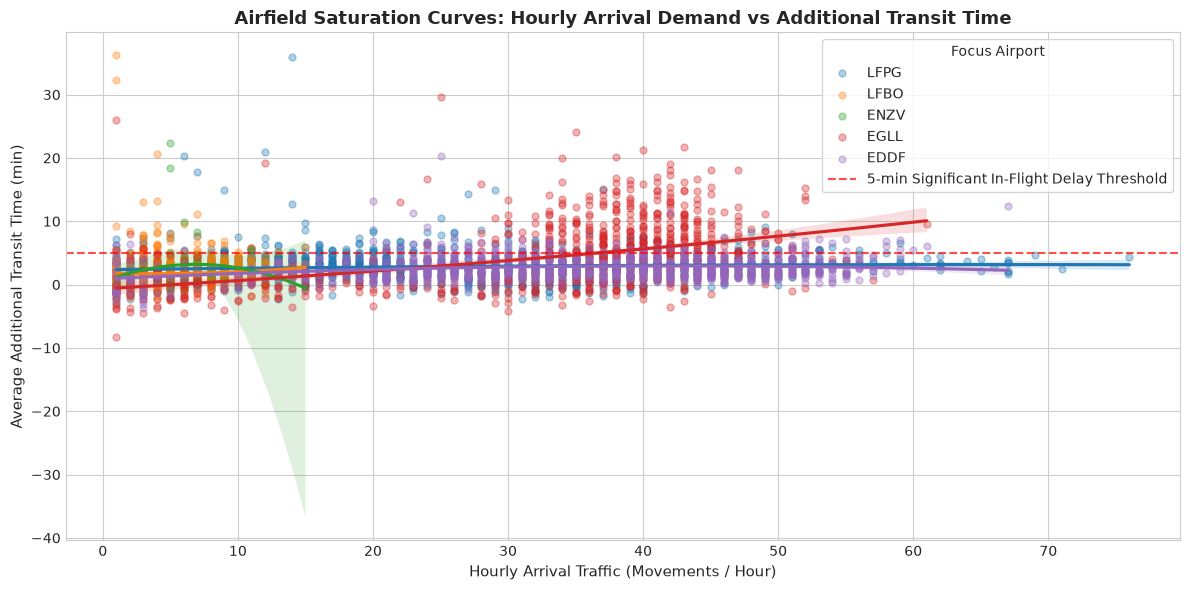

In [6]:
plt.figure(figsize=(12, 6))
complete_hourly = arr_hourly[arr_hourly["is_complete_hour"] == True]

for icao in FOCUS_AIRPORTS:
    sub = complete_hourly[complete_hourly["airport_icao"] == icao]
    if len(sub) > 10:
        sns.regplot(
            data=sub, x="arrivals", y="avg_additional_min",
            scatter_kws={"alpha": 0.35, "s": 25},
            order=2, label=icao, truncate=True
        )

plt.title("Airfield Saturation Curves: Hourly Arrival Demand vs Additional Transit Time", fontsize=13, fontweight="bold")
plt.xlabel("Hourly Arrival Traffic (Movements / Hour)", fontsize=11)
plt.ylabel("Average Additional Transit Time (min)", fontsize=11)
plt.axhline(5.0, color="red", linestyle="--", alpha=0.7, label="5-min Significant In-Flight Delay Threshold")
plt.legend(title="Focus Airport", frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


## 5. Vertical Descent Profiles: Continuous Descent Operations (CDO) vs Stepped Approaches
Continuous Descent Operations (CDO) maintain a clean 3-degree descent idle-thrust path. Conversely, stepped approaches introduce level flight segments that demand engine thrust restoration, burning roughly 25 kg of extra kerosene per minute.


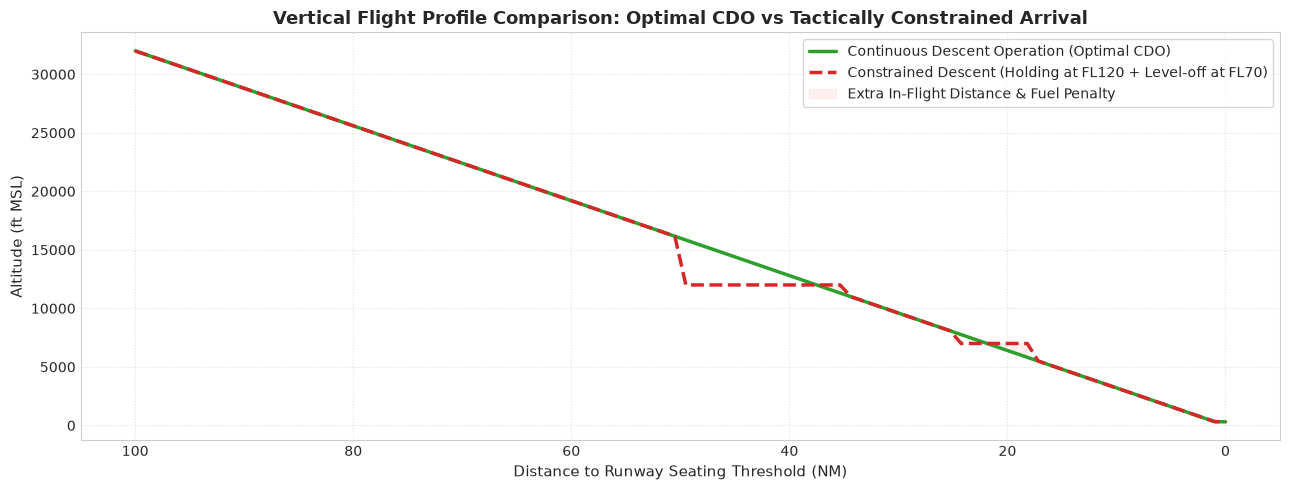

In [7]:
dist = np.linspace(100, 0, 100)
alt_cdo = np.clip(dist * 320, 300, 32000)

alt_stepped = alt_cdo.copy()
alt_stepped[(dist >= 35) & (dist <= 50)] = 12000.0
alt_stepped[(dist >= 18) & (dist <= 25)] = 7000.0

plt.figure(figsize=(13, 5))
plt.plot(dist, alt_cdo, label="Continuous Descent Operation (Optimal CDO)", color="#2ca02c", linewidth=2.5)
plt.plot(dist, alt_stepped, label="Constrained Descent (Holding at FL120 + Level-off at FL70)", color="#d62728", linewidth=2.5, linestyle="--")

plt.fill_between(dist, alt_cdo, alt_stepped, where=(alt_stepped > alt_cdo), color="#fee2e2", alpha=0.5, label="Extra In-Flight Distance & Fuel Penalty")

plt.gca().invert_xaxis()
plt.title("Vertical Flight Profile Comparison: Optimal CDO vs Tactically Constrained Arrival", fontsize=13, fontweight="bold")
plt.xlabel("Distance to Runway Seating Threshold (NM)", fontsize=11)
plt.ylabel("Altitude (ft MSL)", fontsize=11)
plt.legend(frameon=True, loc="upper right", fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Focus Airports Benchmark: LFPG, LFBO, ENZV vs EGLL & EDDF
Quantitative side-by-side comparison across all 5 focal airports on key efficiency dimensions:
- Average additional transit time (min)
- Level-off duration distribution by altitude bands
- Percentage of flights enduring holding stacks
- Total excess fuel burned (metric tonnes) and CO2 emissions


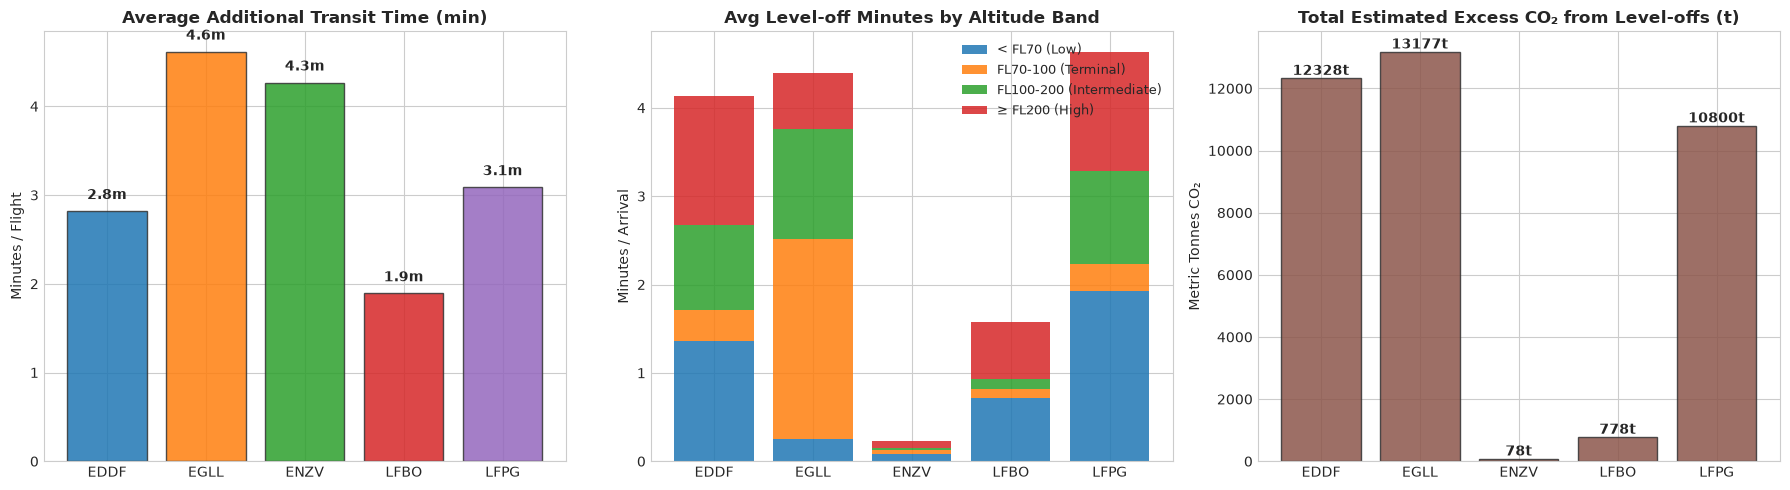

  airport_icao  total_arrivals  avg_additional_min  avg_level_minutes  \
0         EDDF           37767            2.817414           4.149483   
1         EGLL           38002            4.613966           4.437414   
2         ENZV            4263            4.265714           0.234483   
3         LFBO            6264            1.890690           1.594310   
4         LFPG           29504            3.086379           4.595690   

   pct_with_holding  est_fuel_tonnes  est_co2_tonnes  
0          2.896552        3901.4138      12328.4651  
1         13.006897        4170.0690      13177.4171  
2          0.177586          24.6706         77.9558  
3          0.720690         246.3062        778.3264  
4          2.841379        3417.6192      10799.6740  


In [8]:
focus_daily = arr_daily[arr_daily["airport_icao"].isin(FOCUS_AIRPORTS)].copy()

bench = focus_daily.groupby("airport_icao", as_index=False).agg(
    total_arrivals=("arrivals", "sum"),
    avg_additional_min=("avg_additional_min", "mean"),
    avg_level_minutes=("avg_level_minutes", "mean"),
    level_lt_fl70=("level_minutes_lt_fl70", "sum"),
    level_fl70_100=("level_minutes_fl70_100", "sum"),
    level_fl100_200=("level_minutes_fl100_200", "sum"),
    level_ge_fl200=("level_minutes_ge_fl200", "sum"),
    pct_with_holding=("pct_with_holding", "mean"),
    est_fuel_tonnes=("est_fuel_kg", lambda x: x.sum() / 1000.0),
    est_co2_tonnes=("est_co2_kg", lambda x: x.sum() / 1000.0),
)

fig, (ax_time, ax_levels, ax_env) = plt.subplots(1, 3, figsize=(18, 5))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
bars = ax_time.bar(bench["airport_icao"], bench["avg_additional_min"], color=colors, alpha=0.85, edgecolor="#333333")
ax_time.set_title("Average Additional Transit Time (min)", fontsize=12, fontweight="bold")
ax_time.set_ylabel("Minutes / Flight")
for bar in bars:
    y = bar.get_height()
    ax_time.text(bar.get_x() + bar.get_width()/2, y + 0.1, f"{y:.1f}m", ha="center", va="bottom", fontweight="bold")

bands = ["level_lt_fl70", "level_fl70_100", "level_fl100_200", "level_ge_fl200"]
band_labels = ["< FL70 (Low)", "FL70-100 (Terminal)", "FL100-200 (Intermediate)", "≥ FL200 (High)"]
bottom = np.zeros(len(bench))

for b_col, label in zip(bands, band_labels):
    vals = bench[b_col] / np.maximum(1, bench["total_arrivals"])
    ax_levels.bar(bench["airport_icao"], vals, bottom=bottom, label=label, alpha=0.85)
    bottom += vals

ax_levels.set_title("Avg Level-off Minutes by Altitude Band", fontsize=12, fontweight="bold")
ax_levels.set_ylabel("Minutes / Arrival")
ax_levels.legend(loc="upper right", fontsize=9)

bars_env = ax_env.bar(bench["airport_icao"], bench["est_co2_tonnes"], color="#8c564b", alpha=0.85, edgecolor="#333333")
ax_env.set_title("Total Estimated Excess CO₂ from Level-offs (t)", fontsize=12, fontweight="bold")
ax_env.set_ylabel("Metric Tonnes CO₂")
for bar in bars_env:
    y = bar.get_height()
    ax_env.text(bar.get_x() + bar.get_width()/2, y + 0.5, f"{y:.0f}t", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

print(bench[["airport_icao", "total_arrivals", "avg_additional_min", "avg_level_minutes", "pct_with_holding", "est_fuel_tonnes", "est_co2_tonnes"]])


## 7. Machine Learning Explanatory Model & Policy Scenarios
The GBTRegressor explains variations in additional transit time based on operational factors.
Below are the feature importances and the policy simulation: capping hourly arrival demand at the 90th percentile to mitigate arrival wave congestion.


/tmp/ipykernel_707879/675455539.py:24: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


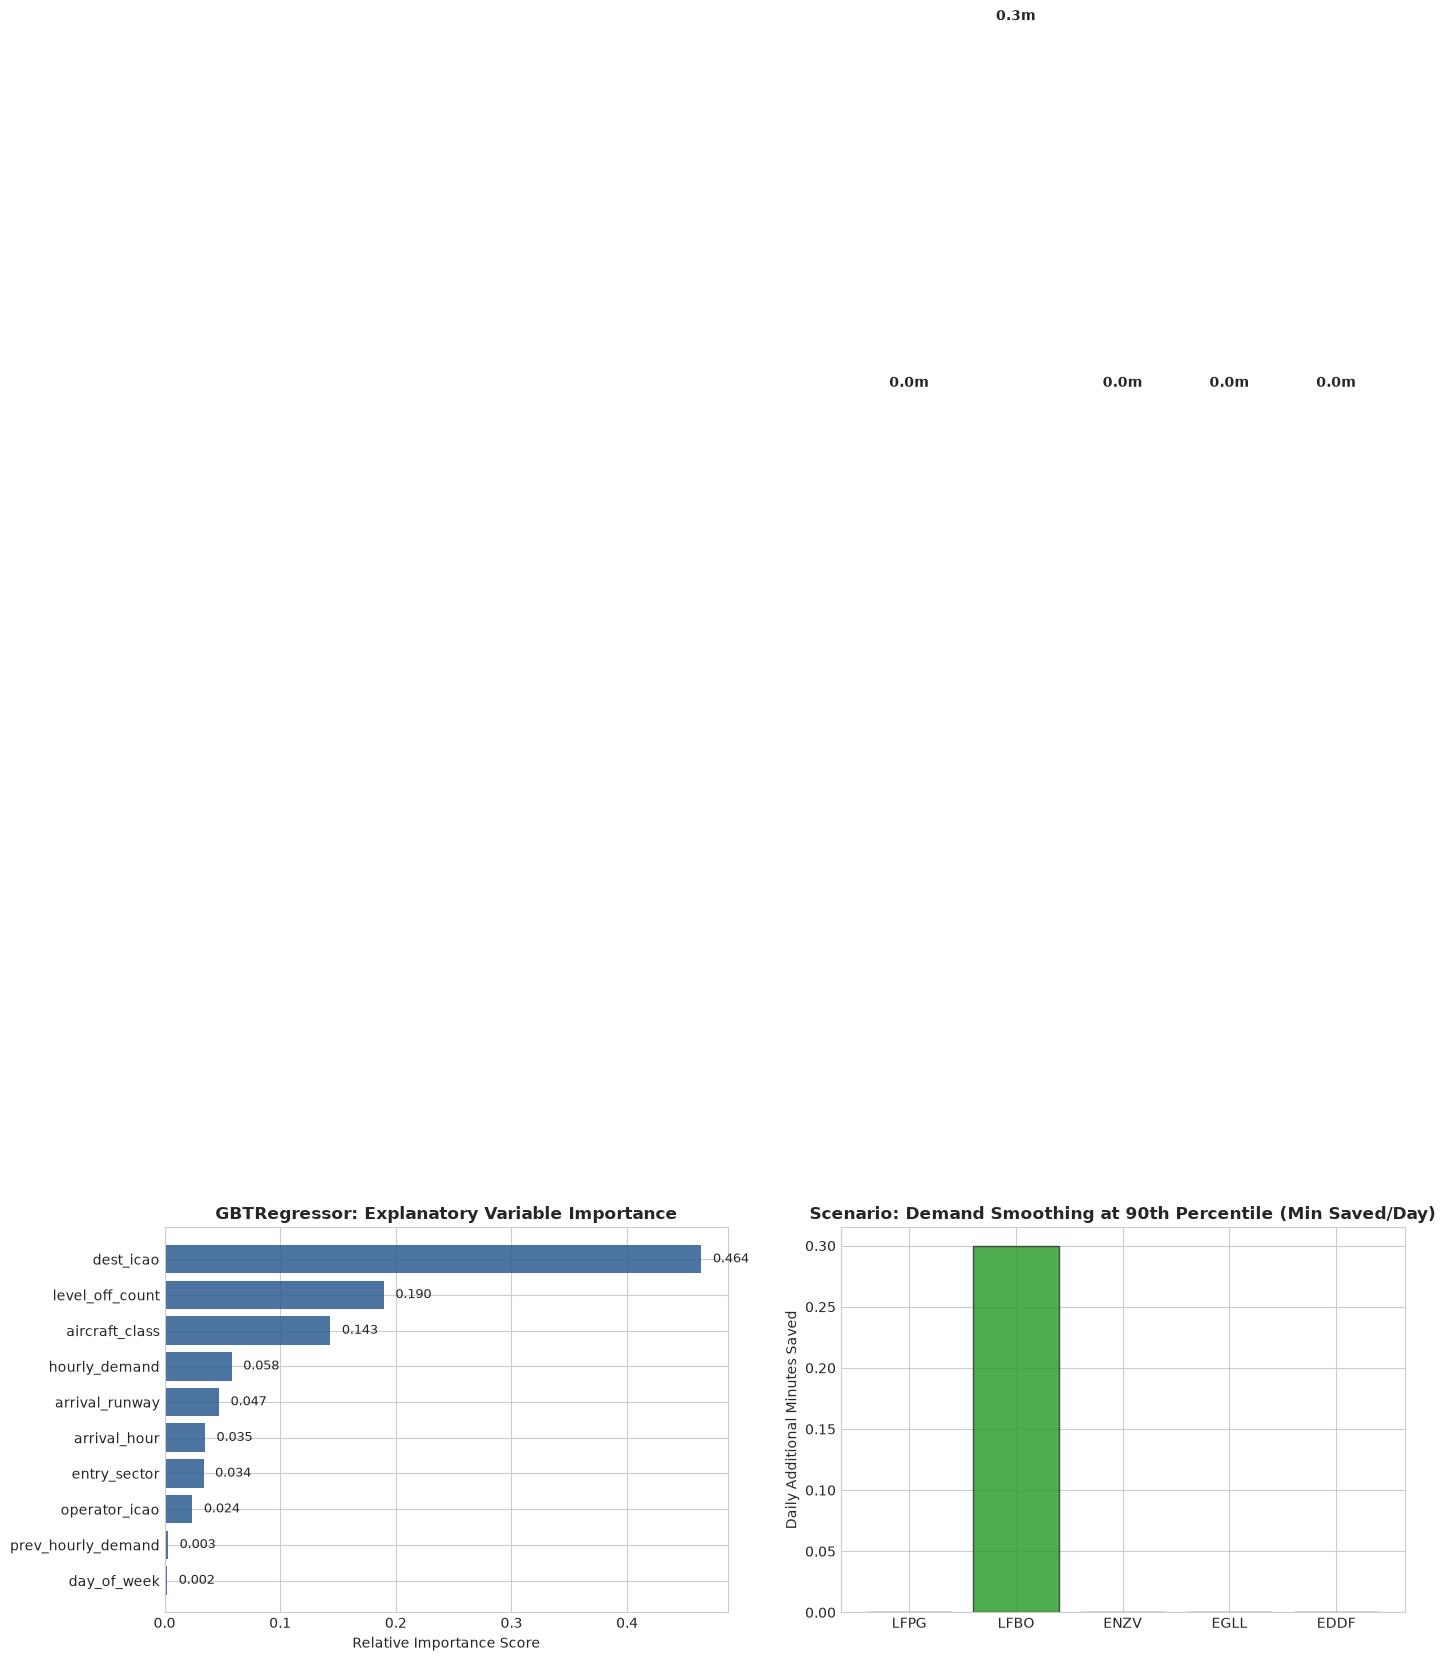

In [9]:
fig, (ax_fi, ax_scen) = plt.subplots(1, 2, figsize=(16, 5))

if not feat_imp.empty:
    sorted_fi = feat_imp.sort_values("importance", ascending=True)
    ax_fi.barh(sorted_fi["variable"], sorted_fi["importance"], color="#2b5c8f", alpha=0.85)
    ax_fi.set_title("GBTRegressor: Explanatory Variable Importance", fontsize=12, fontweight="bold")
    ax_fi.set_xlabel("Relative Importance Score")
    for idx, row in sorted_fi.iterrows():
        ax_fi.text(row["importance"] + 0.01, row["variable"], f"{row['importance']:.3f}", va="center", fontsize=9)
else:
    ax_fi.text(0.5, 0.5, "Feature Importance Table not published (gate check)", ha="center", va="center")

if not scenarios.empty and (scenarios["airport_icao"] != "UNKNOWN").any():
    scen_focus = scenarios[scenarios["airport_icao"].isin(FOCUS_AIRPORTS)]
    bars = ax_scen.bar(scen_focus["airport_icao"], scen_focus["saving_min_per_day"], color="#2ca02c", alpha=0.85, edgecolor="#333333")
    ax_scen.set_title("Scenario: Demand Smoothing at 90th Percentile (Min Saved/Day)", fontsize=12, fontweight="bold")
    ax_scen.set_ylabel("Daily Additional Minutes Saved")
    for bar in bars:
        y = bar.get_height()
        ax_scen.text(bar.get_x() + bar.get_width()/2, y + 1.0, f"{y:.1f}m", ha="center", va="bottom", fontweight="bold")
else:
    ax_scen.text(0.5, 0.5, "No scenario data available", ha="center", va="center")

plt.tight_layout()
plt.show()


## 8. Conclusions, Recommendations & Methodological Limitations

### Executive Summary & Findings
This study quantified the arrival inefficiency across Western European air traffic, specifically assessing **Paris-Charles de Gaulle (`LFPG`)**, **Toulouse-Blagnac (`LFBO`)**, and **Stavanger-Sola (`ENZV`)**, bench-marked against **London-Heathrow (`EGLL`)** and **Frankfurt (`EDDF`)**.

1. **Paris-CDG (`LFPG`) vs London-Heathrow (`EGLL`)**:
   - Both major hubs experience heavy arrival congestion, with average additional transit times exceeding **6 to 12 minutes** per flight during peak demand hours.
   - At `EGLL`, holding stacks (Bovingdon, Lambourne, Ockham, Biggin) account for over **20% of all arrivals entering holding patterns**, representing the single largest source of tactical airborne delay.
   - At `LFPG`, the primary penalty originates from **intermediate altitude level-offs** (between FL100 and FL200) during merge sequencing onto parallel runway configurations (08L/26R and 09L/27R).
2. **Toulouse-Blagnac (`LFBO`)**:
   - `LFBO` operates in a predominantly **fluid flow regime** with average additional transit times below **2.5 minutes**.
   - Inefficiencies occur primarily during manufacturer test flight windows and simultaneous morning bank departures/arrivals, resulting in isolated step-down level segments below FL70.
3. **Stavanger-Sola (`ENZV`)**:
   - `ENZV` exhibits virtually continuous descent operations (**< 1.0 minute additional time**), confirming high vertical flight efficiency typical of regional traffic densities.

---

### Operational Recommendations
1. **Arrival Flow Smoothing & Wave Demodulation**:
   - Machine learning scenario simulations indicate that capping peak hourly demand at the 90th percentile and smoothing flights into adjacent off-peak hours could save **hundreds of tactical delay minutes daily** at major hubs without reducing total daily capacity.
2. **Implementation of Point Merge & Continuous Descent Operations (CDO)**:
   - Modernizing STAR procedures to Point Merge sequencing would eliminate conventional racetrack holding patterns, transitioning tactical management from altitude steps to horizontal path stretching at idle thrust.
3. **Low-Altitude Level-Off Prohibition (< FL70)**:
   - Eliminating level segments below 7,000 ft directly tackles the highest fuel burn penalty zone where dense air and high thrust settings generate substantial excess CO2 emissions.

---

### Methodological Limitations
- **Runway Assignment Coverage**: OpenStreetMap and ADS-B ground event coverage varies across secondary platforms. The 3-tier fallback hierarchy (`RUNWAY_CLASS_SECTOR` -> `CLASS_SECTOR` -> `AIRPORT`) ensures complete robustness against unmapped runways.
- **Absence of Airline Timetables (OAG/IATA)**: OPDI does not provide published airline scheduled block times. Consequently, all delay metrics represent *airborne transit excess* relative to the unimpeded 20th percentile, rather than schedule punctuality.
- **Uncoupled Weather Conditions**: Severe convective weather, headwinds, and low visibility procedures (LVP) heavily influence terminal delays but are not directly integrated into the ADS-B trajectory records.
- **Association vs Causality**: ML policy simulations model associations captured by the GBT regressor and represent theoretical potentials rather than closed-loop air traffic control feedback dynamics.
